# Synthetic Panel Generators — Experimental Bench

**Simulation data generation only.** This notebook extracts the data-generating
processes used by the experiment suite, with every entity name fictional and all
comments in English. No estimator, guard, experiment or reporting code is included.

Two generators live here, both producing the **same column schema** as the baseline
weekly `SKU x region x week` master panel:

| Generator | Purpose |
|---|---|
| `make_lab_panel` | A **single-presentation, single-regime** panel with explicit knobs (number of price moves, move magnitude, true elasticity, pass-through, structural break, competitor activity and reaction). Used to sweep one design dimension at a time. |
| `make_extended_panel` | A **richer portfolio panel** (up to 30 regions, 8 presentations) that fixes, by construction, six limitations of the baseline generator: more regions for the donor pool, heterogeneous and state-dependent pass-through, a regional income component, injected up/down elasticity asymmetry, an actively moving and reacting competitor, and liquidity-driven order refusal. |

Both are accompanied by their **ground-truth tables**, which state what an estimator
run on the panel *should* recover.

### The estimand: why the truth is `beta * rho`, not `beta`

Volume is generated against the **shelf** price, while the price lever (and the price
a demand model regresses on) is the **list** price:

$$\log Q = c + \beta \log\!\big(P^{\text{shelf}}_{\text{real}} / \bar P^{\text{shelf}}\big) + \gamma \log P^{\text{comp}} + \dots$$

$$P^{\text{shelf}}_{\text{real}} = \bar P^{\text{shelf}} \cdot (P^{\text{list}}_{\text{real}}/p_0)^{\rho} \cdot (1 - 0.6\,\text{promo depth})$$

so that

$$\log Q = c + \underbrace{\beta\rho}_{\theta} \log\!\big(P^{\text{list}}_{\text{real}}/p_0\big) + \dots$$

**Consequence.** The elasticity with respect to the list price is $\theta=\beta\rho$.
$\beta$ is the *consumer* elasticity (against the shelf price) and is only recovered
after deconvolving the pass-through $\rho$. In the `sticky_shelf` regime the shelf
price is pinned to a psychological round number, the list price does not enter volume
at all, $\rho = 0$ and therefore $\theta = 0$: that presentation must be **rejected**
by the diagnostics, not estimated.

All figures are in generic currency units; brands, categories and regions are invented.


In [6]:
import warnings; warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

np.set_printoptions(suppress=True)
pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 40)

SEED    = 7      # fixed seed -> full reproducibility
N_WEEKS = 120    # length of the weekly panel

# ---- shared calendar / geography constants ----
REGIONS  = ['North', 'Coastal', 'Central', 'Midlands', 'East', 'South']
REG_TEMP = {'North': 22, 'Coastal': 30, 'Central': 14, 'Midlands': 21, 'East': 26, 'South': 19}

# public holidays per calendar month, used to build the working-days series
HOLIDAYS_BY_MONTH = {1: 1, 2: 0, 3: 1, 4: 1, 5: 1, 6: 1, 7: 0, 8: 1, 9: 0, 10: 0, 11: 1, 12: 2}

print(f"Config -> SEED={SEED} | weeks={N_WEEKS} | base regions={len(REGIONS)}")


Config -> SEED=7 | weeks=120 | base regions=6


## 1 · Ground truth injected in the baseline generator

Reference table for the six-presentation baseline panel: the consumer elasticity
`beta`, the pass-through `rho`, and the resulting list-price estimand
`theta_sellin = beta * rho` per regime. Only the `clean` regime is identifiable by
construction; the other four exist precisely so the diagnostics have something to
reject.


In [7]:
PT_TRUE    = 0.85   # injected pass-through: share of a list-price move reaching the shelf
CROSS_TRUE = 0.30   # cross term on log(competitor price)
FWD_TRUE   = 0.30   # sell-in inflation in the 2 weeks before an increase above 2%

BETA_CONSUMER = {'clean': -1.3, 'sticky_shelf': -1.1, 'weak': -1.0,
                 'confounded': -1.4, 'collinear': -1.2}

# effective pass-through by regime (0 when the shelf price is pinned to a round number)
RHO_BY_REGIME = {'clean': PT_TRUE, 'sticky_shelf': 0.0, 'weak': PT_TRUE,
                 'confounded': PT_TRUE, 'collinear': PT_TRUE}

THETA_SELLIN_TRUE = {k: BETA_CONSUMER[k] * RHO_BY_REGIME[k] for k in BETA_CONSUMER}

PRES_REGIME = {
    'CSD2500_Aurora':  'clean',
    'CSD1500_Aurora':  'clean',
    'CSD1250_Aurora':  'weak',
    'CSD600_Nordia':   'sticky_shelf',
    'WTR600_Vertis':   'confounded',
    'WTR1500_Vertis':  'collinear',
}
PRES_BRAND = {
    'CSD2500_Aurora': 'Aurora', 'CSD1500_Aurora': 'Aurora',
    'CSD1250_Aurora': 'Aurora', 'CSD600_Nordia':  'Nordia',
    'WTR600_Vertis':  'Vertis', 'WTR1500_Vertis': 'Vertis',
}


def truth_by_presentation():
    """Injected ground-truth table, one row per presentation."""
    rows = []
    for pid, reg in PRES_REGIME.items():
        rows.append(dict(pres_id=pid, brand=PRES_BRAND[pid], regime=reg,
                         beta_consumer=BETA_CONSUMER[reg],
                         rho=RHO_BY_REGIME[reg],
                         theta_sellin=THETA_SELLIN_TRUE[reg],
                         identifiable=(reg == 'clean')))
    return pd.DataFrame(rows).set_index('pres_id')


truth_by_presentation()


,brand,regime,beta_consumer,rho,theta_sellin,identifiable
pres_id,,,,,,
CSD2500_Aurora,Aurora,clean,-1.3,0.85,-1.105,True
CSD1500_Aurora,Aurora,clean,-1.3,0.85,-1.105,True
CSD1250_Aurora,Aurora,weak,-1.0,0.85,-0.850,False
CSD600_Nordia,Nordia,sticky_shelf,-1.1,0.00,-0.000,False
WTR600_Vertis,Vertis,confounded,-1.4,0.85,-1.190,False
WTR1500_Vertis,Vertis,collinear,-1.2,0.85,-1.020,False


## 2 · `make_lab_panel` — parameterized single-regime bench

The baseline generator hard-codes the number of price moves, their magnitude and the
true elasticity. Several experiments need to *sweep* exactly those quantities, so this
generator exposes them as arguments and produces a single `clean` presentation across
regions.

Two knobs deserve a note:

- **`comp_moves`** — the baseline DGP gives the competitor only a random walk of 0.4%
  weekly standard deviation, which over 120 weeks leaves a log standard deviation of
  ~1.5%. Against demand noise of 0.05 the cross channel sits **below the noise floor**
  and the cross-elasticity is not identifiable by construction. With `comp_moves > 0`
  the competitor genuinely moves and the competitive bracket becomes testable.
- **`comp_react`** — the competitor's reaction to our own price (the true `r`). With
  `comp_react = 0` the competitor is exogenous and `r_hat ~ 0`, so the identity
  `theta_total - theta_cond = theta_cross * r` holds trivially and tests nothing.

`beta_break = (week, beta_post)` injects a structural break: the elasticity switches
from `beta` to `beta_post` at that week.


In [8]:
def make_lab_panel(rng, W=N_WEEKS, n_moves=10, mag=(0.030, 0.075), beta=-1.3, pt=0.85,
                   cross=0.30, beta_break=None, regions=None, p0=5200,
                   comp_moves=0, comp_mag=(0.04, 0.09), comp_react=0.0,
                   pid='Lab_Pres', brand='LabBrand', category='LabCategory'):
    """Single-presentation `clean` panel with explicit knobs.

    beta_break : None or (week, beta_post). Injects a structural break: the
                 elasticity switches from `beta` to `beta_post` at that week.
    comp_moves : number of DISCRETE competitor price moves (0 = random walk only).
    comp_react : competitor reaction to our own price, with a one-week lag.
    """
    regions = list(regions or REGIONS)
    weeks   = pd.date_range('2023-01-02', periods=W, freq='W-MON')
    woy     = weeks.isocalendar().week.values.astype(int)
    month   = weeks.month.values
    infl    = 100 * (1.0016 ** np.arange(W)) * (1 + rng.normal(0, 0.002, W))
    wage    = 100 * (1.0015 ** np.arange(W))
    holid   = np.array([HOLIDAYS_BY_MONTH[m] for m in month])
    bdays   = np.array([22 - HOLIDAYS_BY_MONTH[m] for m in month])

    # variable cost: level plus a few persistent input shocks
    cost0  = 0.50 * p0
    cshock = np.zeros(W)
    for k in rng.choice(np.arange(10, W - 5), size=4, replace=False):
        cshock[k:] += rng.uniform(0.02, 0.06) * p0 * rng.choice([-1, 1])
    cost_real = np.clip(cost0 + cshock, 0.30 * p0, 0.62 * p0)

    # time profile of beta (constant unless a break is injected)
    beta_t = np.full(W, float(beta))
    if beta_break is not None:
        wk_break, beta_post = beta_break
        beta_t[int(wk_break):] = float(beta_post)

    out = []
    for reg in regions:
        # ---- competitor price
        comp = 1.05 * p0 + np.cumsum(rng.normal(0, 0.004 * p0, W))
        if comp_moves > 0:
            cstep = np.zeros(W)
            for k in rng.choice(np.arange(6, W - 4), size=int(comp_moves), replace=False):
                cstep[k:] += rng.uniform(comp_mag[0], comp_mag[1]) * p0 * rng.choice([-1, 1])
            comp = comp + cstep
        comp = np.clip(comp, 0.70 * p0, 1.45 * p0)

        # ---- promotional calendar
        promo = np.zeros(W, int)
        for k in rng.choice(np.arange(4, W - 3), size=rng.integers(6, 11), replace=False):
            promo[k:k + rng.integers(2, 4)] = 1
        promo = (promo > 0).astype(int)
        pint = promo * rng.uniform(0.10, 0.25)

        # ---- list price: discrete steps off promotional weeks
        base = np.full(W, p0, float)
        step = np.zeros(W)
        nm = int(n_moves)
        if nm > 0:
            cand = [k for k in rng.choice(np.arange(6, W - 4), size=nm, replace=False)
                    if promo[k] == 0]
            for k in cand:
                step[k:] += rng.uniform(mag[0], mag[1]) * p0 * rng.choice([-1, 1])
        list_real = np.clip(base + step, 0.72 * p0, 1.55 * p0)

        if comp_react:
            # the rival follows our own price with a one-week lag
            dlp_own = np.diff(np.log(np.clip(list_real, 1, None)), prepend=np.nan)
            dlp_own = np.nan_to_num(dlp_own)
            react   = np.cumsum(comp_react * np.roll(dlp_own, 1))
            comp    = np.clip(comp * np.exp(react), 0.70 * p0, 1.45 * p0)

        # ---- seasonality via regional temperature
        temp = REG_TEMP[reg] + 6 * np.sin(2 * np.pi * woy / 52 - 1.2) + rng.normal(0, 1.0, W)
        seas = 0.05 * (temp - REG_TEMP[reg])

        # ---- shelf price and demand
        sellout_real = (1.12 * p0) * (list_real / p0) ** pt * (1 - 0.6 * pint)
        sellout      = sellout_real * (infl / 100)
        lv = (np.log(1000) + beta_t * np.log(sellout_real / (1.12 * p0))
              + cross * np.log(comp / (1.05 * p0)) + 0.40 * promo + seas
              + 0.10 * np.log(infl / 100) + rng.normal(0, 0.05, W))
        vol_so = np.exp(lv)

        # ---- forward buying ahead of announced increases above 2%
        dlist = np.diff(np.log(np.clip(list_real, 1, None)), prepend=np.nan)
        fwd   = np.zeros(W)
        for k in np.where(dlist > 0.02)[0]:
            if k - 2 >= 0:
                fwd[k - 2:k] += 0.30
        vol_si = np.clip(vol_so * (1 + fwd) + rng.normal(0, 0.02, W) * vol_so, 1, None)

        out.append(pd.DataFrame({
            'sku_id':            f'{pid}_A',
            'pres_id':           pid,
            'brand':             brand,
            'category':          category,
            'region_id':         reg,
            'date':              weeks,
            'vol_sellin':        vol_si,
            'vol_sellout':       vol_so,
            'price_sellin':      list_real * (infl / 100),
            'price_sellout':     sellout,
            'price_competitor':  comp * (infl / 100),
            'cost_var':          cost_real * (infl / 100),
            'promo_flag':        promo,
            'promo_intensity':   pint,
            'temperature':       temp,
            'inflation_index':   infl,
            'wage_index':        wage,
            'holidays_in_month': holid,
            'business_days':     bdays,
            'channel':           'TRADITIONAL',
            'producer_margin':   (list_real - cost_real) / list_real,
        }))
    return pd.concat(out, ignore_index=True)


def theta_true_lab(beta, pt=0.85):
    """True elasticity of volume with respect to the LIST price."""
    return beta * pt


In [9]:
lab = make_lab_panel(np.random.default_rng(SEED), comp_moves=8, comp_react=0.5)

print(f"Lab panel: {lab.shape} | regions={lab.region_id.nunique()} | weeks={lab.date.nunique()}")
print(f"True theta (list price) = beta * pt = {theta_true_lab(-1.3):.4f}")
lab.head(3)


Lab panel: (720, 21) | regions=6 | weeks=120
True theta (list price) = beta * pt = -1.1050


,sku_id,pres_id,brand,category,region_id,date,vol_sellin,vol_sellout,price_sellin,price_sellout,price_competitor,cost_var,promo_flag,promo_intensity,temperature,inflation_index,wage_index,holidays_in_month,business_days,channel,producer_margin
0,Lab_Pres_A,Lab_Pres,LabBrand,LabCategory,North,2023-01-02,775.892085,782.532930,5200.012794,5824.014329,5442.427052,2600.006397,0,0.0,16.131212,100.000246,100.000000,1,21,TRADITIONAL,0.5
1,Lab_Pres_A,Lab_Pres,LabBrand,LabCategory,North,2023-01-09,706.688709,712.008892,5211.431925,5836.803756,5470.617156,2605.715962,0,0.0,16.455574,100.219845,100.150000,1,21,TRADITIONAL,0.5
2,Lab_Pres_A,Lab_Pres,LabBrand,LabCategory,North,2023-01-16,897.149989,915.021072,5213.793148,5839.448325,5475.826822,2606.896574,0,0.0,19.144838,100.265253,100.300225,1,21,TRADITIONAL,0.5


In [10]:

import numpy as np
import pandas as pd

# 1. Reproducibility
rng = np.random.default_rng(42)

# 2. Dataset settings
n_regions = 10
n_days = 1095
treatment_day = 800
treated_region = "Region_1"

dates = pd.date_range(start="2023-01-01", periods=n_days, freq="D")

records = []

# Shared demand pattern helps create parallel pre-treatment trends
day_number = np.arange(n_days)
seasonality = (
    10 * np.sin(2 * np.pi * day_number / 365.25)
    + 3 * np.sin(2 * np.pi * day_number / 7)
)

# 3. Generate each region
for region_num in range(1, n_regions + 1):
    region_id = f"Region_{region_num}"
    is_treated = region_id == treated_region

    # Small region-specific baseline differences
    baseline_sales = 500 + rng.normal(0, 8)
    base_price = 100 + rng.normal(0, 2)

    # Shared underlying trends, plus modest region-specific noise
    trends = (
        50
        + 8 * np.sin(2 * np.pi * day_number / 365.25)
        + 0.005 * day_number
        + rng.normal(0, 1.5, n_days)
    )

    competitor_price = (
        98
        + 2 * np.sin(2 * np.pi * day_number / 180)
        + rng.normal(0, 1.5, n_days)
    )

    # Price before treatment
    price = base_price + 0.01 * day_number
    price = price.astype(float)

    # Treatment: a 15% increase from day 800 onward
    if is_treated:
        price[treatment_day - 1:] *= 1.15

    # Structural demand model:
    # Sales = baseline - price effect + competitor effect
    #         + trends effect + seasonality + random noise
    noise = rng.normal(0, 8, n_days)

    sales = (
        baseline_sales
        - 2.5 * (price - 100)
        + 1.8 * (competitor_price - 98)
        + 1.2 * (trends - 50)
        + seasonality
        + noise
    )

    sales = np.maximum(sales, 0)

    region_df = pd.DataFrame({
        "Date": dates,
        "Region_ID": region_id,
        "Price": price,
        "Sales_Volume": sales,
        "Competitor_Price": competitor_price,
        "Regional_Google_Trends_Index": trends
    })

    records.append(region_df)

# 4. Combine regions into one dataset
synthetic_data = pd.concat(records, ignore_index=True)

# 5. Add treatment indicator
synthetic_data["Treated"] = (
    synthetic_data["Region_ID"] == treated_region
).astype(int)

synthetic_data["Post_Treatment"] = (
    synthetic_data["Date"] >= dates[treatment_day - 1]
).astype(int)

synthetic_data["Treatment_Effect"] = (
    synthetic_data["Treated"] * synthetic_data["Post_Treatment"]
)

# 6. Inspect the dataset
print("Dataset shape:", synthetic_data.shape)
print("Number of regions:", synthetic_data["Region_ID"].nunique())
print("Days per region:", synthetic_data.groupby("Region_ID").size().unique())
print("Treatment starts:", dates[treatment_day - 1].date())

display(synthetic_data.head())
display(synthetic_data.tail())

# Check treated and donor prices around the intervention
display(
    synthetic_data[
        synthetic_data["Date"].isin(
            dates[[treatment_day - 2, treatment_day - 1]]
        )
    ][["Date", "Region_ID", "Price", "Sales_Volume", "Treated", "Post_Treatment"]]
)

# 7. Save the dataset
synthetic_data.to_csv("synthetic_pricing_data.csv", index=False)
print("Saved as synthetic_pricing_data.csv")


Dataset shape: (10950, 9)
Number of regions: 10
Days per region: [1095]
Treatment starts: 2025-03-10


,Date,Region_ID,Price,Sales_Volume,Competitor_Price,Regional_Google_Trends_Index,Treated,Post_Treatment,Treatment_Effect
0,2023-01-01,Region_1,97.920032,502.330613,98.741835,51.125677,1,0,0
1,2023-01-02,Region_1,97.930032,515.043293,99.530294,51.553460,1,0,0
2,2023-01-03,Region_1,97.940032,512.675252,100.002453,47.358632,1,0,0
3,2023-01-04,Region_1,97.950032,496.126517,99.904206,48.474406,1,0,0
4,2023-01-05,Region_1,97.960032,508.554359,99.199495,50.761804,1,0,0


,Date,Region_ID,Price,Sales_Volume,Competitor_Price,Regional_Google_Trends_Index,Treated,Post_Treatment,Treatment_Effect
10945,2025-12-26,Region_10,109.726344,488.091362,99.863772,55.144445,0,1,0
10946,2025-12-27,Region_10,109.736344,489.036619,99.346749,55.991833,0,1,0
10947,2025-12-28,Region_10,109.746344,483.784653,99.033693,53.608954,0,1,0
10948,2025-12-29,Region_10,109.756344,493.264834,98.167251,55.469583,0,1,0
10949,2025-12-30,Region_10,109.766344,482.278758,100.721869,54.967874,0,1,0


,Date,Region_ID,Price,Sales_Volume,Treated,Post_Treatment
798,2025-03-09,Region_1,105.900032,513.952793,1,0
799,2025-03-10,Region_1,121.796537,481.425328,1,1
1893,2025-03-09,Region_2,107.167733,524.807984,0,0
1894,2025-03-10,Region_2,107.177733,532.335086,0,1
2988,2025-03-09,Region_3,107.827609,492.103277,0,0
2989,2025-03-10,Region_3,107.837609,501.060516,0,1
4083,2025-03-09,Region_4,108.142163,495.916148,0,0
4084,2025-03-10,Region_4,108.152163,490.579952,0,1
5178,2025-03-09,Region_5,111.421010,495.228012,0,0
5179,2025-03-10,Region_5,111.431010,500.022079,0,1


Saved as synthetic_pricing_data.csv


In [5]:
print("Function exists:", "make_lab_panel" in globals())
print("SEED exists:", "SEED" in globals())
print("NumPy exists:", "np" in globals())
print("Pandas exists:", "pd" in globals())

Function exists: False
SEED exists: False
NumPy exists: False
Pandas exists: False


In [11]:

import numpy as np
import pandas as pd

# 1. Reproducibility
rng = np.random.default_rng(42)

# 2. Dataset settings
n_regions = 10
n_days = 1095
treatment_day = 800
treated_region = "Region_1"

dates = pd.date_range(start="2023-01-01", periods=n_days, freq="D")

records = []

# Shared demand pattern helps create parallel pre-treatment trends
day_number = np.arange(n_days)
seasonality = (
    10 * np.sin(2 * np.pi * day_number / 365.25)
    + 3 * np.sin(2 * np.pi * day_number / 7)
)

# 3. Generate each region
for region_num in range(1, n_regions + 1):
    region_id = f"Region_{region_num}"
    is_treated = region_id == treated_region

    # Small region-specific baseline differences
    baseline_sales = 500 + rng.normal(0, 8)
    base_price = 100 + rng.normal(0, 2)

    # Shared underlying trends, plus modest region-specific noise
    trends = (
        50
        + 8 * np.sin(2 * np.pi * day_number / 365.25)
        + 0.005 * day_number
        + rng.normal(0, 1.5, n_days)
    )

    competitor_price = (
        98
        + 2 * np.sin(2 * np.pi * day_number / 180)
        + rng.normal(0, 1.5, n_days)
    )

    # Price before treatment
    price = base_price + 0.01 * day_number
    price = price.astype(float)

    # Treatment: a 15% increase from day 800 onward
    if is_treated:
        price[treatment_day - 1:] *= 1.15

    # Structural demand model:
    # Sales = baseline - price effect + competitor effect
    #         + trends effect + seasonality + random noise
    noise = rng.normal(0, 8, n_days)

    sales = (
        baseline_sales
        - 2.5 * (price - 100)
        + 1.8 * (competitor_price - 98)
        + 1.2 * (trends - 50)
        + seasonality
        + noise
    )

    sales = np.maximum(sales, 0)

    region_df = pd.DataFrame({
        "Date": dates,
        "Region_ID": region_id,
        "Price": price,
        "Sales_Volume": sales,
        "Competitor_Price": competitor_price,
        "Regional_Google_Trends_Index": trends
    })

    records.append(region_df)

# 4. Combine regions into one dataset
synthetic_data = pd.concat(records, ignore_index=True)

# 5. Add treatment indicator
synthetic_data["Treated"] = (
    synthetic_data["Region_ID"] == treated_region
).astype(int)

synthetic_data["Post_Treatment"] = (
    synthetic_data["Date"] >= dates[treatment_day - 1]
).astype(int)

synthetic_data["Treatment_Effect"] = (
    synthetic_data["Treated"] * synthetic_data["Post_Treatment"]
)

# 6. Inspect the dataset
print("Dataset shape:", synthetic_data.shape)
print("Number of regions:", synthetic_data["Region_ID"].nunique())
print("Days per region:", synthetic_data.groupby("Region_ID").size().unique())
print("Treatment starts:", dates[treatment_day - 1].date())

display(synthetic_data.head())
display(synthetic_data.tail())

# Check treated and donor prices around the intervention
display(
    synthetic_data[
        synthetic_data["Date"].isin(
            dates[[treatment_day - 2, treatment_day - 1]]
        )
    ][["Date", "Region_ID", "Price", "Sales_Volume", "Treated", "Post_Treatment"]]
)

# 7. Save the dataset
synthetic_data.to_csv("synthetic_pricing_data.csv", index=False)
print("Saved as synthetic_pricing_data.csv")


Dataset shape: (10950, 9)
Number of regions: 10
Days per region: [1095]
Treatment starts: 2025-03-10


,Date,Region_ID,Price,Sales_Volume,Competitor_Price,Regional_Google_Trends_Index,Treated,Post_Treatment,Treatment_Effect
0,2023-01-01,Region_1,97.920032,502.330613,98.741835,51.125677,1,0,0
1,2023-01-02,Region_1,97.930032,515.043293,99.530294,51.553460,1,0,0
2,2023-01-03,Region_1,97.940032,512.675252,100.002453,47.358632,1,0,0
3,2023-01-04,Region_1,97.950032,496.126517,99.904206,48.474406,1,0,0
4,2023-01-05,Region_1,97.960032,508.554359,99.199495,50.761804,1,0,0


,Date,Region_ID,Price,Sales_Volume,Competitor_Price,Regional_Google_Trends_Index,Treated,Post_Treatment,Treatment_Effect
10945,2025-12-26,Region_10,109.726344,488.091362,99.863772,55.144445,0,1,0
10946,2025-12-27,Region_10,109.736344,489.036619,99.346749,55.991833,0,1,0
10947,2025-12-28,Region_10,109.746344,483.784653,99.033693,53.608954,0,1,0
10948,2025-12-29,Region_10,109.756344,493.264834,98.167251,55.469583,0,1,0
10949,2025-12-30,Region_10,109.766344,482.278758,100.721869,54.967874,0,1,0


,Date,Region_ID,Price,Sales_Volume,Treated,Post_Treatment
798,2025-03-09,Region_1,105.900032,513.952793,1,0
799,2025-03-10,Region_1,121.796537,481.425328,1,1
1893,2025-03-09,Region_2,107.167733,524.807984,0,0
1894,2025-03-10,Region_2,107.177733,532.335086,0,1
2988,2025-03-09,Region_3,107.827609,492.103277,0,0
2989,2025-03-10,Region_3,107.837609,501.060516,0,1
4083,2025-03-09,Region_4,108.142163,495.916148,0,0
4084,2025-03-10,Region_4,108.152163,490.579952,0,1
5178,2025-03-09,Region_5,111.421010,495.228012,0,0
5179,2025-03-10,Region_5,111.431010,500.022079,0,1


Saved as synthetic_pricing_data.csv


In [12]:
pre_treatment = synthetic_data[
    synthetic_data["Date"] < dates[treatment_day - 1]
]

daily_sales = pre_treatment.pivot(
    index="Date",
    columns="Region_ID",
    values="Sales_Volume"
)

print("Pre-treatment sales correlation:")
print(daily_sales.corr().round(2))

print("\nAverage pre-treatment sales by region:")
print(daily_sales.mean().round(2))

Pre-treatment sales correlation:
Region_ID  Region_1  Region_10  Region_2  Region_3  Region_4  Region_5  Region_6  Region_7  Region_8  Region_9
Region_ID                                                                                                     
Region_1       1.00       0.77      0.75      0.75      0.77      0.76      0.76      0.76      0.75      0.75
Region_10      0.77       1.00      0.75      0.76      0.76      0.76      0.75      0.76      0.76      0.76
Region_2       0.75       0.75      1.00      0.75      0.75      0.78      0.76      0.78      0.75      0.77
Region_3       0.75       0.76      0.75      1.00      0.76      0.77      0.75      0.76      0.76      0.76
Region_4       0.77       0.76      0.75      0.76      1.00      0.77      0.76      0.79      0.75      0.78
Region_5       0.76       0.76      0.78      0.77      0.77      1.00      0.77      0.77      0.77      0.77
Region_6       0.76       0.75      0.76      0.75      0.76      0.77      1.0

In [13]:
import matplotlib.pyplot as plt

pre_treatment = synthetic_data[
    synthetic_data["Date"] < dates[treatment_day - 1]
]

daily_avg = pre_treatment.groupby(
    ["Date", "Region_ID"]
)["Sales_Volume"].mean().reset_index()

for region in sorted(daily_avg["Region_ID"].unique()):
    region_data = daily_avg[daily_avg["Region_ID"] == region]
    plt.plot(
        region_data["Date"],
        region_data["Sales_Volume"],
        alpha=0.6,
        label=region
    )

plt.title("Pre-Treatment Sales Trends Across Regions")
plt.xlabel("Date")
plt.ylabel("Sales Volume")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [14]:
%pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 187.9 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 245.8 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 245.8 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 245.8 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 245.8 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 223.7 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ------------------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


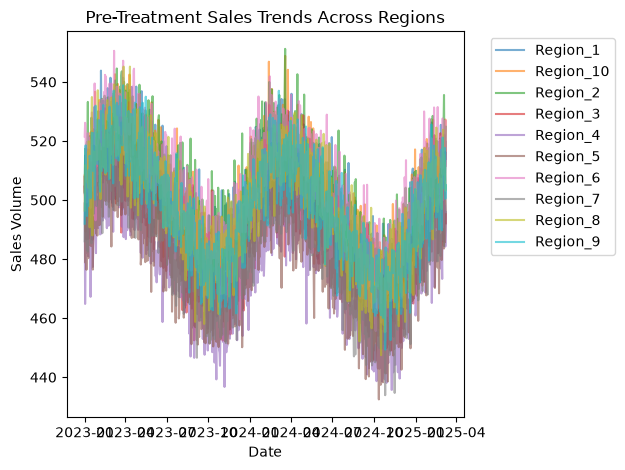

In [15]:
import matplotlib.pyplot as plt

pre_treatment = synthetic_data[
    synthetic_data["Date"] < dates[treatment_day - 1]
]

daily_avg = pre_treatment.groupby(
    ["Date", "Region_ID"]
)["Sales_Volume"].mean().reset_index()

for region in sorted(daily_avg["Region_ID"].unique()):
    region_data = daily_avg[daily_avg["Region_ID"] == region]
    plt.plot(
        region_data["Date"],
        region_data["Sales_Volume"],
        alpha=0.6,
        label=region
    )

plt.title("Pre-Treatment Sales Trends Across Regions")
plt.xlabel("Date")
plt.ylabel("Sales Volume")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

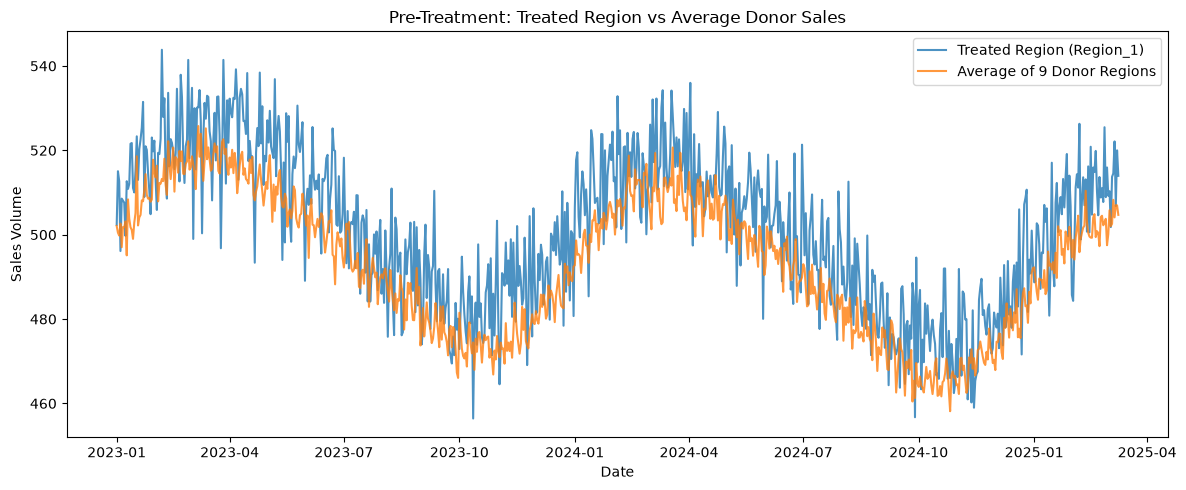

In [16]:
# Average sales of the 9 donor regions for each day
donor_avg = (
    pre_treatment[pre_treatment["Region_ID"] != "Region_1"]
    .groupby("Date")["Sales_Volume"]
    .mean()
)

# Sales of the treated region
treated_sales = (
    pre_treatment[pre_treatment["Region_ID"] == "Region_1"]
    .set_index("Date")["Sales_Volume"]
)

plt.figure(figsize=(12, 5))
plt.plot(treated_sales.index, treated_sales.values,
         label="Treated Region (Region_1)", alpha=0.8)
plt.plot(donor_avg.index, donor_avg.values,
         label="Average of 9 Donor Regions", alpha=0.8)

plt.title("Pre-Treatment: Treated Region vs Average Donor Sales")
plt.xlabel("Date")
plt.ylabel("Sales Volume")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
pre_diff = treated_sales - donor_avg

print("Mean difference:", round(pre_diff.mean(), 2))
print("Mean absolute difference:", round(pre_diff.abs().mean(), 2))
print("Correlation:", round(treated_sales.corr(donor_avg), 3))
print("RMSE:", round(np.sqrt((pre_diff ** 2).mean()), 2))

Mean difference: 8.21
Mean absolute difference: 10.22
Correlation: 0.854
RMSE: 12.44


In [18]:
%pip install scipy

     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     ------ --------------------------------- 10.2/61.2 kB ? eta -:--:--
     ------ --------------------------------- 10.2/61.2 kB ? eta -:--:--
     ------ --------------------------------- 10.2/61.2 kB ? eta -:--:--
     ------------------- ------------------ 30.7/61.2 kB 131.3 kB/s eta 0:00:01
     ------------------- ------------------ 30.7/61.2 kB 131.3 kB/s eta 0:00:01
     ------------------- ------------------ 30.7/61.2 kB 131.3 kB/s eta 0:00:01
     ------------------- ------------------ 30.7/61.2 kB 131.3 kB/s eta 0:00:01
     ------------------------------- ------ 51.2/61.2 kB 119.1 kB/s eta 0:00:01
     -------------------------------------- 61.2/61.2 kB 141.8 kB/s eta 0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ------------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
print("Shape:", synthetic_data.shape)
print("Missing values:", synthetic_data.isnull().sum().sum())
print("Duplicate rows:", synthetic_data.duplicated().sum())
print("Unique dates:", synthetic_data["Date"].nunique())
print("Unique regions:", synthetic_data["Region_ID"].nunique())

Shape: (10950, 9)
Missing values: 0
Duplicate rows: 0
Unique dates: 1095
Unique regions: 10


In [20]:
print("Column data types:")
print(synthetic_data.dtypes)

print("\nSummary statistics:")
display(synthetic_data.describe())

print("\nDate range:")
print(synthetic_data["Date"].min(), "to", synthetic_data["Date"].max())

print("\nRows per region:")
print(synthetic_data.groupby("Region_ID").size())

Column data types:
Date                            datetime64[us]
Region_ID                                  str
Price                                  float64
Sales_Volume                           float64
Competitor_Price                       float64
Regional_Google_Trends_Index           float64
Treated                                  int64
Post_Treatment                           int64
Treatment_Effect                         int64
dtype: object

Summary statistics:


,Date,Price,Sales_Volume,Competitor_Price,Regional_Google_Trends_Index,Treated,Post_Treatment,Treatment_Effect
count,10950,10950.000000,10950.000000,10950.000000,10950.000000,10950.000000,10950.000000,10950.000000
mean,2024-07-01 00:00:00,105.870125,488.788696,97.998920,52.764228,0.100000,0.270320,0.027032
min,2023-01-01 00:00:00,97.920032,412.943128,91.235378,38.770141,0.000000,0.000000,0.000000
25%,2023-10-01 00:00:00,102.616545,473.313829,96.506312,47.878775,0.000000,0.000000,0.000000
50%,2024-07-01 00:00:00,105.434836,489.277532,98.019304,52.749538,0.000000,0.000000,0.000000
75%,2025-04-01 00:00:00,108.423220,505.418287,99.450024,57.636972,0.000000,1.000000,0.000000
max,2025-12-30 00:00:00,125.189037,551.207328,105.770787,67.561229,1.000000,1.000000,1.000000
std,NaN,4.562423,22.319023,2.060156,5.677261,0.300014,0.444145,0.162184



Date range:
2023-01-01 00:00:00 to 2025-12-30 00:00:00

Rows per region:
Region_ID
Region_1     1095
Region_10    1095
Region_2     1095
Region_3     1095
Region_4     1095
Region_5     1095
Region_6     1095
Region_7     1095
Region_8     1095
Region_9     1095
dtype: int64


In [21]:
treatment_date = dates[799]

print("Treatment date:", treatment_date)

print("\nTreatment indicator counts:")
print(synthetic_data.groupby(
    ["Region_ID", "Treated", "Post_Treatment"]
).size())

print("\nTreated region prices around treatment:")
display(
    synthetic_data[
        (synthetic_data["Region_ID"] == "Region_1")
        & (synthetic_data["Date"].between(
            dates[798], dates[800]
        ))
    ][["Date", "Price", "Treated", "Post_Treatment"]]
)

Treatment date: 2025-03-10 00:00:00

Treatment indicator counts:
Region_ID  Treated  Post_Treatment
Region_1   1        0                 799
                    1                 296
Region_10  0        0                 799
                    1                 296
Region_2   0        0                 799
                    1                 296
Region_3   0        0                 799
                    1                 296
Region_4   0        0                 799
                    1                 296
Region_5   0        0                 799
                    1                 296
Region_6   0        0                 799
                    1                 296
Region_7   0        0                 799
                    1                 296
Region_8   0        0                 799
                    1                 296
Region_9   0        0                 799
                    1                 296
dtype: int64

Treated region prices around treatment:


,Date,Price,Treated,Post_Treatment
798,2025-03-09,105.900032,1,0
799,2025-03-10,121.796537,1,1
800,2025-03-11,121.808037,1,1


In [22]:
print("Final dataset columns:")
print(synthetic_data.columns.tolist())

print("\nTreatment effect counts:")
print(synthetic_data["Treatment_Effect"].value_counts())

print("\nTreatment effect by region:")
print(
    synthetic_data.groupby("Region_ID")["Treatment_Effect"]
    .sum()
)

print("\nFinal dataset shape:")
print(synthetic_data.shape)

Final dataset columns:
['Date', 'Region_ID', 'Price', 'Sales_Volume', 'Competitor_Price', 'Regional_Google_Trends_Index', 'Treated', 'Post_Treatment', 'Treatment_Effect']

Treatment effect counts:
Treatment_Effect
0    10654
1      296
Name: count, dtype: int64

Treatment effect by region:
Region_ID
Region_1     296
Region_10      0
Region_2       0
Region_3       0
Region_4       0
Region_5       0
Region_6       0
Region_7       0
Region_8       0
Region_9       0
Name: Treatment_Effect, dtype: int64

Final dataset shape:
(10950, 9)


In [23]:
# Save the final dataset
synthetic_data.to_csv("synthetic_pricing_data.csv", index=False)

# Read the saved file back to verify it
verified_data = pd.read_csv("synthetic_pricing_data.csv")

print("File saved and checked!")
print("Shape:", verified_data.shape)
print("Missing values:", verified_data.isnull().sum().sum())
print("Duplicate rows:", verified_data.duplicated().sum())
print("Regions:", verified_data["Region_ID"].nunique())
print("Date range:", verified_data["Date"].min(), "to", verified_data["Date"].max())

File saved and checked!
Shape: (10950, 9)
Missing values: 0
Duplicate rows: 0
Regions: 10
Date range: 2023-01-01 to 2025-12-30


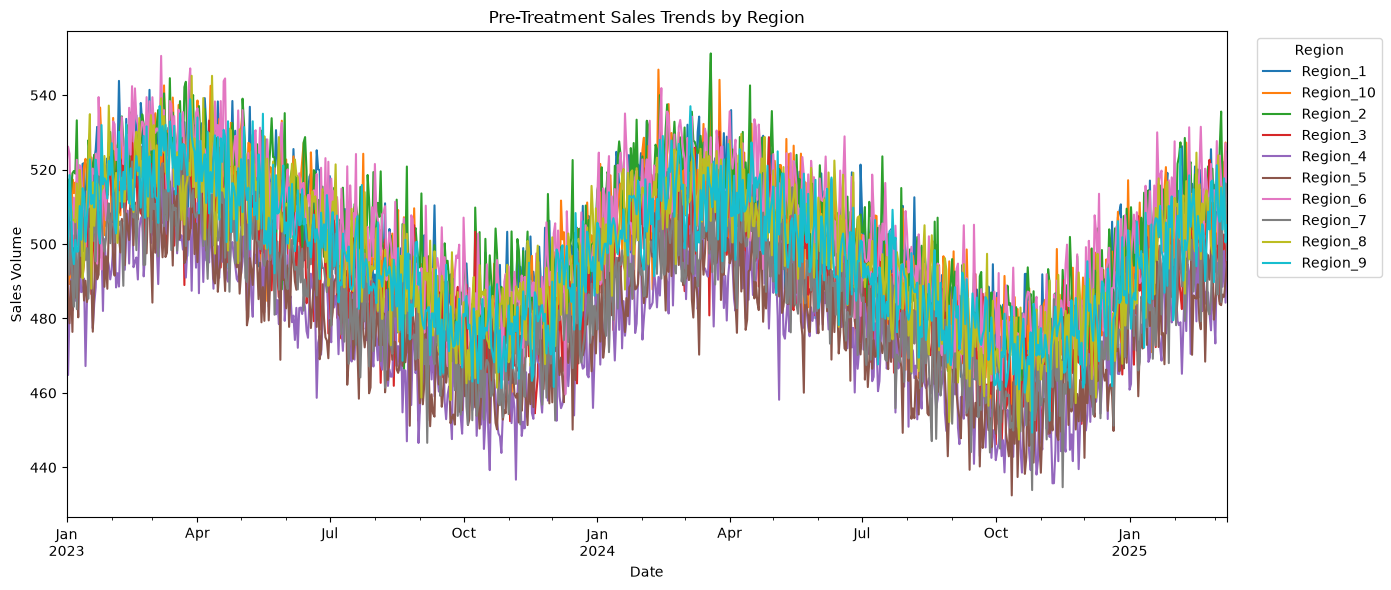

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the saved dataset
df = pd.read_csv("synthetic_pricing_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Keep only the period before treatment
treatment_date = pd.Timestamp("2025-03-10")
pre_data = df[df["Date"] < treatment_date]

# Calculate average sales for each region by date
sales_trends = pre_data.pivot(
    index="Date",
    columns="Region_ID",
    values="Sales_Volume"
)

# Plot all regions before treatment
sales_trends.plot(figsize=(14, 6))

plt.title("Pre-Treatment Sales Trends by Region")
plt.xlabel("Date")
plt.ylabel("Sales Volume")
plt.legend(title="Region", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [25]:
# Separate treated and donor regions
treated_sales = sales_trends["Region_1"]

donor_sales = sales_trends.drop(columns=["Region_1"])

# Average sales across all donor regions
average_donor_sales = donor_sales.mean(axis=1)

# Calculate pre-treatment fit metrics
correlation = treated_sales.corr(average_donor_sales)

rmse = (
    ((treated_sales - average_donor_sales) ** 2).mean()
) ** 0.5

mae = (
    (treated_sales - average_donor_sales).abs().mean()
)

print("Pre-treatment fit against average donor:")
print(f"Correlation: {correlation:.3f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")

Pre-treatment fit against average donor:
Correlation: 0.854
RMSE: 12.44
MAE: 10.22


## 3 · `make_extended_panel` — portfolio generator

Fixes, by construction, six limitations of the baseline generator — all of them CPU
hours rather than a quarter of data negotiation:

1. **30 regions instead of 6.** The floor of a permutation p-value drops from
   1/C(6,3) to 1/C(30,8), and the synthetic-control donor pool becomes real.
2. **Pass-through heterogeneous by region *and* state-dependent** on the retailer's
   margin: exercises the Markov chain and the variance attribution.
3. **Regional income with its own variation**: the cash-pressure index stops being a
   single national series, so the screening test can actually run.
4. **Injected asymmetry `eps_up != eps_dn`**: the Dual Beta estimator has something to
   recover instead of measuring its own noise.
5. **Competitor with discrete moves and a reaction function**: cross-elasticity rises
   above the noise floor.
6. **Liquidity-driven order refusal**: an observable extensive margin, so a two-part
   model has signal to recover.

`seed_noise` is the key knob for coverage work: passing it draws demand (and sell-in)
noise from a **separate** RNG. Fixing `rng` and varying `seed_noise` resamples the noise
while **holding the design fixed** — identical prices, promotions, competitor and
temperature. That is the only way to measure coverage **conditional on the design**,
which is the property a within-panel bootstrap claims to have; dispersion measured
across seeds instead mixes in the variation of the realized design.


In [5]:
EXT_REGIONS_30 = [f'R{i:02d}' for i in range(1, 31)]

EXT_PORTFOLIO = [
    # pres_id,        brand,   category,        beta,  mean_rho, regime
    ('EXT_A1_Alpha',  'Alpha', 'Carbonated',    -1.30, 0.85, 'clean'),
    ('EXT_A2_Alpha',  'Alpha', 'Carbonated',    -1.15, 0.80, 'clean'),
    ('EXT_A3_Alpha',  'Alpha', 'Carbonated',    -1.00, 0.85, 'weak'),
    ('EXT_B1_Beta',   'Beta',  'Carbonated',    -1.10, 0.00, 'sticky_shelf'),
    ('EXT_C1_Gamma',  'Gamma', 'Bottled Water', -1.40, 0.85, 'confounded'),
    ('EXT_C2_Gamma',  'Gamma', 'Bottled Water', -1.20, 0.85, 'collinear'),
    ('EXT_C3_Gamma',  'Gamma', 'Bottled Water', -1.25, 0.60, 'clean'),
    ('EXT_D1_Delta',  'Delta', 'Bottled Water', -0.90, 0.85, 'clean'),
]

EXT_REGIME_CFG = {
    'clean':        dict(n_moves=10, mag=(0.030, 0.075), promo_conf=0.0, comp_follow=0.0),
    'weak':         dict(n_moves=2,  mag=(0.004, 0.009), promo_conf=0.0, comp_follow=0.0),
    'sticky_shelf': dict(n_moves=10, mag=(0.030, 0.075), promo_conf=0.0, comp_follow=0.0),
    'confounded':   dict(n_moves=10, mag=(0.030, 0.075), promo_conf=0.9, comp_follow=0.0),
    'collinear':    dict(n_moves=10, mag=(0.030, 0.075), promo_conf=0.0, comp_follow=0.95),
}


def make_extended_panel(rng, W=N_WEEKS, n_reg=30, portfolio=None, p0=5200,
                        rho_sd=0.12, rho_state=0.35, asym=0.0,
                        comp_moves=8, comp_mag=(0.04, 0.09), comp_react=0.5,
                        income_reg_sd=0.020, refusal=0.0, cross=0.30, beta_break=None,
                        seed_noise=None, sigma_demand=0.05):
    """Extended synthetic panel. Same columns as `make_lab_panel`, plus truth columns.

    rho_sd        : dispersion of rho across regions (0 = homogeneous).
    rho_state     : state dependence — how much rho rises when the retailer's margin
                    falls below its target band.
    asym          : injected asymmetry. eps_up = beta*(1-asym), eps_dn = beta*(1+asym).
                    With 0 the Dual Beta must return symmetry; with 0.25 it must detect
                    a gap of 0.5*|beta|.
    income_reg_sd : sd of the REGIONAL component of real income. With 0 the cash-pressure
                    index is national and its t statistic is not finite.
    refusal       : intensity of liquidity-driven order refusal (extensive margin).
    seed_noise    : if given, demand and sell-in noise come from a SEPARATE RNG, so the
                    noise can be resampled while the design is held fixed.
    """
    regions = EXT_REGIONS_30[:int(n_reg)]
    rngn    = np.random.default_rng(seed_noise) if seed_noise is not None else rng
    port    = list(portfolio if portfolio is not None else EXT_PORTFOLIO)

    weeks   = pd.date_range('2023-01-02', periods=W, freq='W-MON')
    woy     = weeks.isocalendar().week.values.astype(int)
    month   = weeks.month.values
    day_m   = weeks.day.values.astype(float)
    infl    = 100 * (1.0016 ** np.arange(W)) * (1 + rng.normal(0, 0.002, W))
    holid   = np.array([HOLIDAYS_BY_MONTH.get(m, 1) for m in month])
    bdays   = np.array([22 - HOLIDAYS_BY_MONTH.get(m, 1) for m in month])

    # income: national component plus a region-specific one
    wage_nat = 100 * (1.0015 ** np.arange(W))
    wage_reg = {r: wage_nat * np.exp(np.cumsum(rng.normal(0, income_reg_sd, W)))
                for r in regions}

    # True cash pressure: pay-cycle calendar plus regional real-income erosion.
    # Income is standardized POOLED (mean and sd over all regions at once), not
    # within region: standardizing per region would erase exactly the regional
    # level variation this generator exists to inject, and the index would collapse
    # back to a national series.
    cp_cal = -np.minimum(np.abs(day_m - 15), np.abs(day_m - 30))
    cp_cal = (cp_cal - cp_cal.mean()) / max(cp_cal.std(), 1e-9)
    _w_all = np.concatenate([np.log(wage_reg[r]) for r in regions])
    _w_mu, _w_sd = float(_w_all.mean()), float(max(_w_all.std(), 1e-9))

    # rho by region: heterogeneous, truncated to [0, 1]
    rho_mult = {r: float(np.clip(1.0 + rng.normal(0, rho_sd), 0.25, 1.6)) for r in regions}
    temp_reg = {r: float(rng.uniform(13, 31)) for r in regions}

    out = []
    for (pid, brand, cat, beta, rho0, regime) in port:
        cfg    = dict(EXT_REGIME_CFG.get(regime, EXT_REGIME_CFG['clean']))
        beta_t = np.full(W, float(beta))
        if beta_break is not None:
            wk, bpost = beta_break
            beta_t[int(wk):] = float(bpost)
        eps_up, eps_dn = beta * (1 - asym), beta * (1 + asym)

        cost0  = 0.50 * p0
        cshock = np.zeros(W)
        for k in rng.choice(np.arange(10, W - 5), size=4, replace=False):
            cshock[k:] += rng.uniform(0.02, 0.06) * p0 * rng.choice([-1, 1])
        cost_real = np.clip(cost0 + cshock, 0.30 * p0, 0.62 * p0)

        for reg in regions:
            # ---- competitor
            comp = 1.05 * p0 + np.cumsum(rng.normal(0, 0.004 * p0, W))
            if comp_moves > 0:
                cstep = np.zeros(W)
                for k in rng.choice(np.arange(6, W - 4), size=int(comp_moves), replace=False):
                    cstep[k:] += rng.uniform(*comp_mag) * p0 * rng.choice([-1, 1])
                comp = comp + cstep

            # ---- promotions
            promo = np.zeros(W, int)
            for k in rng.choice(np.arange(4, W - 3), size=rng.integers(6, 11), replace=False):
                promo[k:k + rng.integers(2, 4)] = 1
            promo = (promo > 0).astype(int)
            pint = promo * rng.uniform(0.10, 0.25)

            # ---- list price
            step = np.zeros(W)
            nm = int(cfg['n_moves'])
            if nm > 0:
                cand = rng.choice(np.arange(6, W - 4), size=nm, replace=False)
                for k in cand:
                    # confounding with promotions: the move snaps onto a promo week
                    if cfg['promo_conf'] > 0 and rng.random() < cfg['promo_conf']:
                        pk = np.where(promo > 0)[0]
                        if len(pk):
                            k = int(rng.choice(pk))
                    elif promo[k] == 1 and cfg['promo_conf'] == 0:
                        continue
                    step[k:] += rng.uniform(*cfg['mag']) * p0 * rng.choice([-1, 1])
            list_real = np.clip(p0 + step, 0.72 * p0, 1.55 * p0)

            # collinearity with the competitor
            if cfg['comp_follow'] > 0:
                lr = np.log(np.clip(comp / (1.05 * p0), 1e-6, None))
                list_real = np.clip(p0 * np.exp(cfg['comp_follow'] * lr),
                                    0.72 * p0, 1.55 * p0)
            # competitor reaction to our own price
            if comp_react:
                dlp = np.nan_to_num(np.diff(np.log(np.clip(list_real, 1, None)), prepend=np.nan))
                comp = comp * np.exp(np.cumsum(comp_react * np.roll(dlp, 1)))
            comp = np.clip(comp, 0.70 * p0, 1.45 * p0)

            # ---- pass-through: heterogeneous and dependent on the margin state
            rho_r = 0.0 if regime == 'sticky_shelf' else float(
                np.clip(rho0 * rho_mult[reg], 0.0, 1.0))
            marg_target = 0.12
            so   = np.empty(W)
            marg = np.empty(W)
            so_prev = 1.12 * p0
            for k in range(W):
                m_prev = (so_prev - list_real[k]) / max(so_prev, 1e-6)
                # if the margin falls below target, the retailer passes through MORE
                rho_k = np.clip(rho_r * (1.0 + rho_state * (marg_target - m_prev) / marg_target),
                                0.0, 1.2) if rho_r > 0 else 0.0
                so[k] = (1.12 * p0) * (list_real[k] / p0) ** rho_k * (1 - 0.6 * pint[k])
                if rho_r == 0:
                    so[k] = (1.12 * p0) * (1 - 0.6 * pint[k])   # pinned to the round number
                marg[k] = (so[k] - list_real[k]) / max(so[k], 1e-6)
                so_prev = so[k]

            # ---- REALIZED pass-through. With `rho_state` > 0 transmission depends on
            # the margin, so rho_r is no longer the estimand: the estimand is the
            # log-log slope actually realized in the series. It is computed and stored
            # here so the truth an estimator is scored against is the truth of THIS
            # panel and not the one in the config dict. Comparing against the config
            # would report generator dispersion as estimator bias.
            _lso_c = np.log(np.clip(so / ((1.12 * p0) * (1 - 0.6 * pint)), 1e-9, None))
            _llist = np.log(np.clip(list_real / p0, 1e-9, None))
            _vv    = float(np.var(_llist))
            rho_eff = (float(np.cov(_lso_c, _llist)[0, 1] / _vv)
                       if _vv > 1e-12 else float(rho_r))

            # ---- demand, with Houck asymmetry on the shelf price
            lso = np.log(np.clip(so / (1.12 * p0), 1e-9, None))
            if abs(asym) > 1e-12:
                d  = np.diff(lso, prepend=lso[0])
                up = np.cumsum(np.clip(d, 0, None))
                dn = np.cumsum(np.clip(d, None, 0))
                effect = eps_up * up + eps_dn * dn
            else:
                effect = beta_t * lso

            temp  = temp_reg[reg] + 6 * np.sin(2 * np.pi * woy / 52 - 1.2) + rng.normal(0, 1.0, W)
            seas  = 0.05 * (temp - temp_reg[reg])
            wag_r = wage_reg[reg]
            cp_true = cp_cal - (np.log(wag_r) - _w_mu) / _w_sd

            lv = (np.log(1000) + effect + cross * np.log(comp / (1.05 * p0))
                  + 0.40 * promo + seas + 0.10 * np.log(infl / 100)
                  + 0.05 * cp_true + rngn.normal(0, sigma_demand, W))
            vol_so = np.exp(lv)

            # ---- sell-in: forward buying plus liquidity-driven order refusal
            dlist = np.nan_to_num(np.diff(np.log(np.clip(list_real, 1, None)), prepend=np.nan))
            fwd = np.zeros(W)
            for k in np.where(dlist > 0.02)[0]:
                if k - 2 >= 0:
                    fwd[k - 2:k] += 0.30
            vol_si = np.clip(vol_so * (1 + fwd) + rngn.normal(0, 0.02, W) * vol_so, 1, None)
            if refusal > 0:
                # probability of NOT ordering rises as cash gets tight
                pz = 1.0 / (1.0 + np.exp(-(refusal * (-cp_true) - 1.6)))
                vol_si = np.where(rngn.random(W) < pz, 0.0, vol_si)

            out.append(pd.DataFrame({
                'sku_id':            f'{pid}_A',
                'pres_id':           pid,
                'brand':             brand,
                'category':          cat,
                'region_id':         reg,
                'date':              weeks,
                'vol_sellin':        vol_si,
                'vol_sellout':       vol_so,
                'price_sellin':      list_real * (infl / 100),
                'price_sellout':     so * (infl / 100),
                'price_competitor':  comp * (infl / 100),
                'cost_var':          cost_real * (infl / 100),
                'promo_flag':        promo,
                'promo_intensity':   pint,
                'temperature':       temp,
                'inflation_index':   infl,
                'wage_index':        wag_r,
                'holidays_in_month': holid,
                'business_days':     bdays,
                'channel':           'TRADITIONAL',
                'producer_margin':   (list_real - cost_real) / list_real,
                # ---- ground-truth columns (never fed to any estimator) ----
                'retailer_margin':   marg,
                'rho_base':          rho_r,
                'rho_realized':      rho_eff,
                'beta_true':         float(beta),
                'eps_up_true':       float(eps_up),
                'eps_dn_true':       float(eps_dn),
                'theta_realized':    float(beta) * rho_eff,
                'cash_pressure_true': cp_true,
                'regime_true':       regime,
            }))
    return pd.concat(out, ignore_index=True)


### 3·b · Ground truth of the extended generator

Two readings of the truth, and the difference matters:

- **`truth_from_panel`** reads `rho` **from the generated panel**. With heterogeneous,
  state-dependent pass-through, `rho` is no longer the number in the config dict — the
  estimand is the log-log slope actually realized in the series. This is the table an
  estimator should be scored against.
- **`truth_from_config`** reports the *intended* truth from the portfolio definition.
  Useful for documentation, but scoring against it would report generator dispersion as
  estimator bias.


In [6]:
def truth_from_panel(panel, asym=0.0):
    """Truth READ from the generated panel, not from the config dict."""
    rows = []
    for pid, gg in panel.groupby('pres_id'):
        rho  = float(gg.rho_realized.mean())
        beta = float(gg.beta_true.iloc[0])
        reg  = str(gg.regime_true.iloc[0])
        eu   = float(gg.eps_up_true.iloc[0])
        ed   = float(gg.eps_dn_true.iloc[0])
        rows.append(dict(
            pres_id=pid, brand=str(gg.brand.iloc[0]), regime=reg,
            beta_consumer=beta,
            rho=rho, rho_sd_regional=float(gg.groupby('region_id').rho_realized.first().std()),
            theta_sellin=beta * rho,
            theta_up=eu * rho, theta_dn=ed * rho,
            theta_asymmetry=abs(eu * rho - ed * rho),
            identifiable=(reg == 'clean')))
    return pd.DataFrame(rows).set_index('pres_id')


def truth_from_config(portfolio=None, asym=0.0, rho_sd=0.0):
    """Intended truth of the extended generator, one row per presentation.

    theta = beta * rho is the estimand against the list price. With rho_sd > 0 the
    effective rho varies by region, so per-presentation theta is an average and is
    flagged as such.
    """
    port = list(portfolio if portfolio is not None else EXT_PORTFOLIO)
    rows = []
    for (pid, brand, cat, beta, rho0, regime) in port:
        rho = 0.0 if regime == 'sticky_shelf' else rho0
        eu, ed = beta * (1 - asym), beta * (1 + asym)
        rows.append(dict(pres_id=pid, brand=brand, category=cat, regime=regime,
                         beta_consumer=beta, rho=rho, theta_sellin=beta * rho,
                         eps_up=eu, eps_dn=ed,
                         # what a Dual Beta on the LIST price should see
                         theta_up=eu * rho, theta_dn=ed * rho,
                         theta_asymmetry=abs(eu * rho - ed * rho),
                         rho_heterogeneous=bool(rho_sd > 0),
                         identifiable=(regime == 'clean')))
    return pd.DataFrame(rows).set_index('pres_id')


In [7]:
ext = make_extended_panel(np.random.default_rng(SEED), asym=0.25, refusal=0.6)

print(f"Extended panel: {ext.shape} | presentations={ext.pres_id.nunique()} "
      f"| regions={ext.region_id.nunique()} | weeks={ext.date.nunique()}")

truth_from_panel(ext).round(4)


Extended panel: (28800, 30) | presentations=8 | regions=30 | weeks=120


,brand,regime,beta_consumer,rho,rho_sd_regional,theta_sellin,theta_up,theta_dn,theta_asymmetry,identifiable
pres_id,,,,,,,,,,
EXT_A1_Alpha,Alpha,clean,-1.30,0.8574,0.1641,-1.1146,-0.8359,-1.3932,0.5573,True
EXT_A2_Alpha,Alpha,clean,-1.15,0.8249,0.1479,-0.9487,-0.7115,-1.1858,0.4743,True
EXT_A3_Alpha,Alpha,weak,-1.00,0.8798,0.1217,-0.8798,-0.6598,-1.0997,0.4399,False
EXT_B1_Beta,Beta,sticky_shelf,-1.10,0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,False
EXT_C1_Gamma,Gamma,confounded,-1.40,0.8587,0.1833,-1.2021,-0.9016,-1.5027,0.6011,False
EXT_C2_Gamma,Gamma,collinear,-1.20,0.8892,0.1365,-1.0670,-0.8003,-1.3338,0.5335,False
EXT_C3_Gamma,Gamma,clean,-1.25,0.6397,0.1305,-0.7996,-0.5997,-0.9995,0.3998,True
EXT_D1_Delta,Delta,clean,-0.90,0.8539,0.1435,-0.7685,-0.5764,-0.9606,0.3842,True


In [8]:
ext.head(3)


,sku_id,pres_id,brand,category,region_id,date,vol_sellin,vol_sellout,price_sellin,price_sellout,price_competitor,cost_var,promo_flag,promo_intensity,temperature,inflation_index,wage_index,holidays_in_month,business_days,channel,producer_margin,retailer_margin,rho_base,rho_realized,beta_true,eps_up_true,eps_dn_true,theta_realized,cash_pressure_true,regime_true
0,EXT_A1_Alpha_A,EXT_A1_Alpha,Alpha,Carbonated,R01,2023-01-02,0.000000,620.635922,5200.012794,5824.014329,5425.154681,2600.006397,0,0.0,20.779103,100.000246,100.178773,1,21,TRADITIONAL,0.5,0.107143,0.843628,0.928389,-1.3,-0.975,-1.625,-1.206906,-1.626204,clean
1,EXT_A1_Alpha_A,EXT_A1_Alpha,Alpha,Carbonated,R01,2023-01-09,0.000000,815.478471,5211.431925,5836.803756,5450.047952,2605.715962,0,0.0,21.764329,100.219845,99.150076,1,21,TRADITIONAL,0.5,0.107143,0.843628,0.928389,-1.3,-0.975,-1.625,-1.206906,0.258265,clean
2,EXT_A1_Alpha_A,EXT_A1_Alpha,Alpha,Carbonated,R01,2023-01-16,976.380791,966.171707,5213.793148,5839.448325,5437.890802,2606.896574,0,0.0,22.895808,100.265253,99.063524,1,21,TRADITIONAL,0.5,0.107143,0.843628,0.928389,-1.3,-0.975,-1.625,-1.206906,1.566077,clean
